# Advanced Apex Project-2 — Week-2

**Name:** Anil Ghatge  
**BITS ID:** 2025EM1200153    
**Project title:** Credit Risk and Load Default Prediction  
**Selected problem ID:** P1  
**Submission stage:** Week 2 — project outline and initial dataset understanding


## **1. Project Title**

## **Credit Risk & Loan Default Prediction**

### **2. Problem Statement**

Financial institutions need to assess a borrower's risk before approving a loan. This problem is about building a
supervised classification model that predicts the probability of loan default using demographic, financial, and
credit-history features, so that lenders can make more informed approval decisions.

### **3. Business Goal:**
This project aims to develop a supervised classification model for credit risk assessment and loan default prediction using demographics, financial and credit-history features. Utilizing a Kaggle dataset, the model will analyze various factors to identify borrowers who are likely to default on their loans, thereby helping financial institutions minimize losses and make more informed lending decisions.

**Donwload Dataset**

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import kagglehub
import pandas as pd
import os

# Download the LendingClub dataset
path = kagglehub.dataset_download("habiburrohman/lendingclub-loan-dataset")

# Locate and load the CSV files within the downloaded dataset folder
csv_files = []
for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith('.csv'):
            csv_files.append(os.path.join(root, file))

if csv_files:
    # Load the first available CSV file
    file_path = csv_files[0]
    df = pd.read_csv(file_path)
    print(f"Successfully loaded: {file_path}")
    print(f"DataFrame shape: {df.shape}")
    display(df.head())
else:
    print(f"No CSV files found in download path: {path}")
    # List all files for inspection
    for root, dirs, files in os.walk(path):
        for file in files:
            print(os.path.join(root, file))

100%|██████████| 59.5M/59.5M [00:00<00:00, 74.6MB/s]

Extracting files...



/tmp/ipykernel_689/2060505574.py:18: DtypeWarning: Columns (20) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


Successfully loaded: /root/.cache/kagglehub/datasets/habiburrohman/lendingclub-loan-dataset/versions/1/loan_data_2007_2014.csv
DataFrame shape: (466285, 75)


,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,...,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,B,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,B,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **4. Dataset Details: LendingClub Loan Dataset**

* **Dataset Name:** LendingClub Loan Dataset (2007-2014)
* **Source/Link:** Kaggle ([`habiburrohman/lendingclub-loan-dataset`](https://www.kaggle.com/datasets/habiburrohman/lendingclub-loan-dataset))
* **Approximate Size:**
  * **Number of rows (records):** 466,285
  * **Number of columns (features):** 75
* **Target Variable:**
  * `loan_status` (Categorical variable containing values like 'Fully Paid', 'Charged Off', 'Default', 'Does not meet the credit policy. Status:Fully Paid', etc.). For binary classification, this is typically mapped to `1` (Default/Charged Off) and `0` (Fully Paid).
* **Brief Description of Important Features:**
  * `loan_amnt`: The listed amount of the loan applied for by the borrower.
  * `term`: The number of payments on the loan (either 36 or 60 months).
  * `int_rate`: Interest rate on the loan.
  * `installment`: The monthly payment owed by the borrower if the loan originates.
  * `grade` / `sub_grade`: LendingClub assigned loan grade and subgrade.
  * `emp_length`: Employment length in years (e.g., < 1 year, 10+ years).
  * `home_ownership`: The home ownership status provided by the borrower during registration (e.g., RENT, OWN, MORTGAGE).
  * `annual_inc`: The self-reported annual income provided by the borrower during registration.
  * `verification_status`: Indicates if the co-borrowers' joint income was verified, not verified, or if the income source was verified.
  * `dti`: A ratio calculated using the borrower’s total monthly debt payments on the total debt obligations, excluding mortgage and the requested LC loan, divided by the borrower’s self-reported monthly income.
  * `addr_state`: The state provided by the borrower in the loan application.

In [9]:
# Let's inspect the target distribution and key properties of the columns we highlighted
import pandas as pd

# 1. Dimensions check
rows, cols = df.shape
print(f"=== LendingClub Dataset Dimensions ===")
print(f"Total Records (Rows): {rows:,}")
print(f"Total Features (Columns): {cols}\n")

# 2. Inspect Target Variable Distribution
print("=== Target Variable ('loan_status') Distribution ===")
target_counts = df['loan_status'].value_counts(dropna=False)
target_percent = df['loan_status'].value_counts(normalize=True, dropna=False) * 100
target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage (%)': target_percent.round(2)
})
display(target_summary)

# 3. Analyze Key Features listed in section 4
key_features = [
    'loan_amnt', 'term', 'int_rate', 'installment', 'grade',
    'sub_grade', 'emp_length', 'home_ownership', 'annual_inc',
    'verification_status', 'dti', 'addr_state'
]

print("\n=== Integrity Check on Crucial Columns ===")
feature_analysis = []
for col in key_features:
    if col in df.columns:
        missing_count = df[col].isnull().sum()
        missing_pct = (missing_count / rows) * 100
        dtype = str(df[col].dtype)
        num_unique = df[col].nunique()
        feature_analysis.append({
            'Feature': col,
            'Dtype': dtype,
            'Unique Values': num_unique,
            'Missing Count': missing_count,
            'Missing (%)': f"{missing_pct:.3f}%"
        })
    else:
        feature_analysis.append({
            'Feature': col,
            'Dtype': 'NOT FOUND',
            'Unique Values': 0,
            'Missing Count': 0,
            'Missing (%)': '100%'
        })

display(pd.DataFrame(feature_analysis))

=== LendingClub Dataset Dimensions ===
Total Records (Rows): 466,285
Total Features (Columns): 75

=== Target Variable ('loan_status') Distribution ===


,Count,Percentage (%)
loan_status,,
Current,224226,48.09
Fully Paid,184739,39.62
Charged Off,42475,9.11
Late (31-120 days),6900,1.48
In Grace Period,3146,0.67
Does not meet the credit policy. Status:Fully Paid,1988,0.43
Late (16-30 days),1218,0.26
Default,832,0.18
Does not meet the credit policy. Status:Charged Off,761,0.16



=== Integrity Check on Crucial Columns ===


,Feature,Dtype,Unique Values,Missing Count,Missing (%)
0,loan_amnt,int64,1352,0,0.000%
1,term,object,2,0,0.000%
2,int_rate,float64,506,0,0.000%
3,installment,float64,55622,0,0.000%
4,grade,object,7,0,0.000%
5,sub_grade,object,35,0,0.000%
6,emp_length,object,11,21008,4.505%
7,home_ownership,object,6,0,0.000%
8,annual_inc,float64,31901,4,0.001%
9,verification_status,object,3,0,0.000%


### **5. Initial Understanding of the Dataset & Problem Overview**

**Problem:** The primary objective is to build an analytical framework to predict loan default status (`loan_status`). Lending institutions require predictive modeling to assess the risk profile of individual applicants, thereby minimizing credit losses and maximizing the overall health of their loan portfolio.

**Initial Observations on the LendingClub Dataset:**
* **Large Scale:** With 466,285 records and 75 features, the dataset provides a rich historical basis for training complex models.
* **Feature Sparsity & Redundancy:** There are several identifier columns (such as `id`, `member_id`, `Unnamed: 0`) and high-dimensionality features that likely contain substantial missing values (e.g., `all_util`). Feature selection and dimensionality reduction will be critical.
* **The Target Variable (`loan_status`):** The target feature is a multi-class string. To formulate this as a binary credit risk model (e.g., 'Will Default' vs. 'Will Pay'), we will need to carefully define which statuses constitute a positive default event (such as `Charged Off`, `Default`, `Late (31-120 days)`) versus positive repayment behavior.
* **Data Cleaning Requirements:** The presence of warnings (like mixed data types on column 20) indicates that some columns need strict type casting, missing value imputation, or standardizing (e.g., handling symbols or text in numeric columns like interest rates or employment length).

In [12]:
# 1. Diagnose the mixed-type warning in Column 20
warn_col_name = df.columns[20]
print(f"=== Mixed-Type Warning Column Analysis ===")
print(f"Column at index 20: '{warn_col_name}'")
print(f"Unique values preview (first 10): {df[warn_col_name].dropna().unique()[:10]}")
print(f"Type breakdown in raw records: {df[warn_col_name].apply(type).value_counts()}\n")

# 2. Identify High-Sparsity Columns (> 80% Missing Values)
print("=== Sparsity & Missing Data Profile ===")
null_pcts = (df.isnull().sum() / len(df)) * 100
high_null_cols = null_pcts[null_pcts > 80.0].sort_values(ascending=False)
print(f"Columns with more than 80% missing values ({len(high_null_cols)} features):")
display(pd.DataFrame({'Missing %': high_null_cols.round(2)}))

# 3. Identify and verify Redundant Identifier Keys
identifiers = ['id', 'member_id', 'Unnamed: 0']
print("\n=== Identifier / Metadata Columns Check ===")
for ident in identifiers:
    if ident in df.columns:
        print(f"Column '{ident}': {df[ident].nunique():,} unique values (Is Unique Key: {df[ident].nunique() == len(df)})")

# 4. Highlight Potential Post-Origination Leakage Features
# These are updated *after* loan approval (e.g., payments made, collection actions, status updates)
potential_leakage = [
    'funding_amnt', 'funded_amnt_inv', 'out_prncp', 'out_prncp_inv',
    'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int',
    'total_rec_late_fee', 'recoveries', 'collection_recovery_fee',
    'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d'
]

existing_leakage_cols = [col for col in potential_leakage if col in df.columns]
print(f"\n=== Potential Post-Origination Leakage Columns Detected ({len(existing_leakage_cols)} features) ===")
print(", ".join(existing_leakage_cols))

=== Mixed-Type Warning Column Analysis ===
Column at index 20: 'desc'
Unique values preview (first 10): ['  Borrower added on 12/22/11 > I need to upgrade my business technologies.<br>'
 '  Borrower added on 12/22/11 > I plan to use this money to finance the motorcycle i am looking at. I plan to have it paid off as soon as possible/when i sell my old bike. I only need this money because the deal im looking at is to good to pass up.<br><br>  Borrower added on 12/22/11 > I plan to use this money to finance the motorcycle i am looking at. I plan to have it paid off as soon as possible/when i sell my old bike.I only need this money because the deal im looking at is to good to pass up. I have finished college with an associates degree in business and its takingmeplaces<br>'
 "  Borrower added on 12/21/11 > to pay for property tax (borrow from friend, need to pay back) & central A/C need to be replace. I'm very sorry to let my loan expired last time.<br>"
 "  Borrower added on 12/21/11 > I p

,Missing %
annual_inc_joint,100.00
dti_joint,100.00
il_util,100.00
verification_status_joint,100.00
open_acc_6m,100.00
open_il_6m,100.00
open_il_12m,100.00
open_il_24m,100.00
mths_since_rcnt_il,100.00
total_bal_il,100.00



=== Identifier / Metadata Columns Check ===
Column 'id': 466,285 unique values (Is Unique Key: True)
Column 'member_id': 466,285 unique values (Is Unique Key: True)
Column 'Unnamed: 0': 466,285 unique values (Is Unique Key: True)

=== Potential Post-Origination Leakage Columns Detected (14 features) ===
funded_amnt_inv, out_prncp, out_prncp_inv, total_pymnt, total_pymnt_inv, total_rec_prncp, total_rec_int, total_rec_late_fee, recoveries, collection_recovery_fee, last_pymnt_d, last_pymnt_amnt, next_pymnt_d, last_credit_pull_d


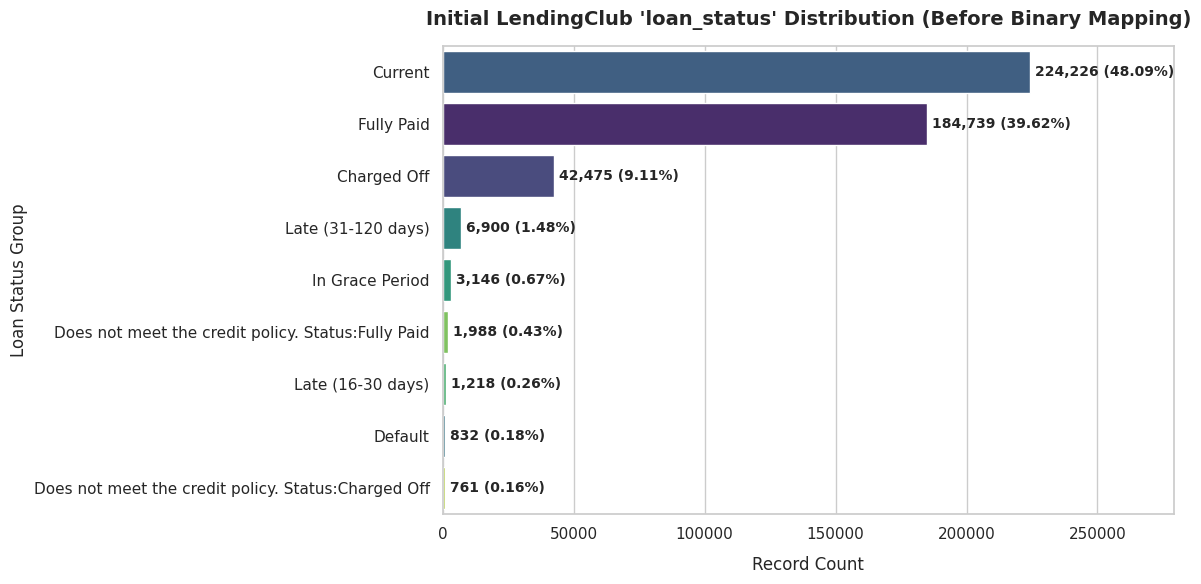

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Sort categories for clean display
target_order = df['loan_status'].value_counts().index

# Create horizontal barplot
ax = sns.countplot(
    y='loan_status',
    data=df,
    order=target_order,
    palette='viridis',
    hue='loan_status',
    legend=False
)

# Add percentage labels to the bars
total_samples = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_width() / total_samples:.2f}%'
    x = p.get_width() + 2000
    y = p.get_y() + p.get_height() / 2
    ax.annotate(f'{p.get_width():,.0f} ({percentage})', (x, y), va='center', ha='left', fontsize=10, fontweight='semibold')

plt.title("Initial LendingClub 'loan_status' Distribution (Before Binary Mapping)", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("Record Count", fontsize=12, labelpad=10)
plt.ylabel("Loan Status Group", fontsize=12)
plt.xlim(0, max(df['loan_status'].value_counts()) + 55000)
plt.tight_layout()
plt.show()

### **6. Proposed Machine Learning Workflow**

To build a robust, predictive framework for loan default classification, we will execute a rigorous, structured machine learning workflow consisting of the following sequential stages:

```
Data Loading ➔ Data Preprocessing ➔ EDA ➔ Feature Engineering ➔ Baseline Model ➔ Advanced Models ➔ Hyperparameter Tuning ➔ Evaluation & Interpretation
```

#### **Step 1: Data Loading & Verification**
* Programmatic ingestion of the raw LendingClub CSV file into a pandas DataFrame.
* Initial structural checks (`df.shape`, column names, data types, memory usage, and column-wise null percentage counts).

#### **Step 2: Data Preprocessing & Target Definition**
* **Defining the Target Variable:** Transform the multi-class `loan_status` column into a binary label: `1` for default risk (e.g., 'Charged Off', 'Default', 'Late') and `0` for low risk (e.g., 'Fully Paid'). We will filter out active or indeterminate accounts if they introduce noise.
* **Handling Missing Data:** Assess columns with high missing rates and drop features that do not meet a specific threshold (e.g., >50% nulls). Impute remaining missing values using appropriate imputation strategies (median for skewed numerical values, mode/constant for categorical attributes).
* **Data Cleaning & Formatting:** Cast numeric-like columns represented as strings (such as converting `'36 months'` to `36`, and mapping `'10+ years'` to `10`) to actual numerical datatypes.

#### **Step 3: Exploratory Data Analysis (EDA)**
* **Target Distribution:** Check for class imbalance between default and non-default classes to design resampling or metric strategies.
* **Feature Analysis:** Visualize correlations and distributions of critical variables (such as debt-to-income ratio, interest rates, and loan amounts) in relation to the target class.

#### **Step 4: Feature Engineering & Encoding**
* **Categorical Encoding:** Implement One-Hot Encoding for nominal variables with low-cardinality (e.g., `home_ownership`, `verification_status`) and Target/Label Encoding for ordinal or high-cardinality values.
* **Feature Scaling:** Normalize/Standardize numeric features using `RobustScaler` or `StandardScaler` to ensure stability for distance-based and gradient-descent algorithms.

#### **Step 5: Model Selection & Baseline Development**
* Split the preprocessed dataset into structured training, validation, and test splits (e.g., 70/15/15) keeping class balance intact using stratification.
* Establish a fast baseline classifier (e.g., **Logistic Regression**) to set a benchmark performance.

#### **Step 6: Advanced Model Development**
* Train ensemble and gradient-boosted models, such as **Random Forest**, **LightGBM**, or **XGBoost**, which handle non-linear interactions and class imbalances natively well.

#### **Step 7: Hyperparameter Tuning & Optimization**
* Fine-tune the champion model using techniques like Bayesian Optimization, Grid Search, or Random Search combined with Cross-Validation.

#### **Step 8: Final Model Evaluation & Interpretation**
* Assess generalization capabilities using robust metrics like **Precision, Recall, F1-Score, and PR-AUC** (which are more informative than accuracy for imbalanced data).
* Explain the logic behind predictions using feature importance and **SHAP values** to guarantee credit decision transparency.

### **7. Tools & Technologies**

To implement this end-to-end machine learning pipeline, we will utilize the following tools and libraries:

* **Programming Language:**
  * **Python**: The core language for writing the pipeline.
* **Data Manipulation & Analysis:**
  * **Pandas**: For reading the large CSV, data preprocessing, handling missing values, and structuring features.
  * **NumPy**: For optimized vector and matrix mathematical computations.
* **Data Visualization:**
  * **Matplotlib**: For basic static visualizations and plotting structures.
  * **Seaborn**: For statistical representations, density plots, correlation matrices, and aesthetic analytical visuals.
* **Machine Learning & Modeling:**
  * **Scikit-learn**: For dataset splitting, feature scaling, encoding categorical variables, cross-validation, hyperparameter tuning, baseline model development (Logistic Regression), and evaluating classifier performance metrics.
  * **LightGBM / XGBoost**: High-performance gradient boosted decision trees for modeling structural tabular data with high predictive accuracy.
* **Model Interpretation:**
  * **SHAP (SHapley Additive exPlanations)**: For explaining individual and global model predictions to fulfill financial risk compliance standards.

### **8. Expected Challenges & Modeling Assumptions**

Developing a high-performing and regulatory-compliant credit risk model on the LendingClub dataset involves several key analytical challenges and assumptions:

#### **A. Extreme Class Imbalance**
* **Challenge:** The majority of loans in the dataset are successfully 'Fully Paid'. Default events (e.g., 'Charged Off' or 'Default') represent a minor percentage of the dataset.
* **Impact:** Classifiers can easily optimize for overall accuracy by simply predicting every loan as non-defaulting. We will have to prioritize evaluation metrics like the **Area Under the Precision-Recall Curve (PR-AUC)** and utilize techniques like weighted loss functions or resampling (e.g., SMOTE).

#### **B. Potential Data Leakage (Post-Origination Features)**
* **Challenge:** The dataset contains numerous features that are updated *after* a loan has been approved and funded (e.g., `recoveries`, `collection_recovery_fee`, `last_pymnt_amnt`, `next_pymnt_d`).
* **Impact:** Using these features to predict default will cause data leakage because these outcomes are only known after default occurs. Identifying and excluding post-origination columns during preprocessing is critical to building a realistic model meant for credit decisioning at the time of application.

#### **C. High Dimensionality and Null Sparsity**
* **Challenge:** Out of 75 columns, many columns have high ratios of missing values (some exceed 90%, such as `mths_since_last_major_derog` or Joint Application metrics). Additionally, high-cardinality categorical variables (like zip code or state) add complexity.
* **Impact:** Training models with highly sparse columns can degrade performance and increase training time. We must set a robust threshold to prune empty features early on.

#### **D. Text-to-Numeric Parsing**
* **Challenge:** Informative variables are stored as strings (e.g., `'36 months'` for `term`, `'10+ years'` for `emp_length`).
* **Impact:** These require custom regular expression parsing and mapping functions to transform them into numeric values without losing ordering information.

#### **E. Computational Overhead**
* **Challenge:** Running cross-validation and hyperparameter search algorithms on nearly 466,000 rows can be computationally expensive and time-consuming in standard environments.
* **Impact:** We must select highly optimized algorithms and potentially downsample or perform efficient validation split checks during exploration.

### **9. References & Dataset Sources**

* **LendingClub Dataset Source:**
  * Hosted on Kaggle by Habibur Rohman: [LendingClub Loan Dataset (2007-2014)](https://www.kaggle.com/datasets/habiburrohman/lendingclub-loan-dataset)
* **Original Publisher:**
  * LendingClub Statistics and Historical Archive: [LendingClub Official Website](https://www.lendingclub.com/)